In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

df = pd.read_csv("../data/interim/listings_parsed_v6.csv")
print(len(df))   # expect 183490

183490


In [3]:
df["is_ward"] = df["municipality"].str.endswith("区").astype(int)
df["region"] = df["municipality"].map(
    lambda x: "ward" if x.endswith("区") else ("city" if x.endswith("市") else "town_village"))

In [4]:
df.to_csv("../data/interim/listings_parsed_v7.csv", index=False)

In [5]:
cols = ["Price_yen", "area_m2", "age_years", "is_new", "floor_min", "stories_above",
        "walk_min_nearest", "municipality", "n_rooms"]
df = pd.read_csv("../data/interim/listings_parsed_v7.csv", usecols=cols)

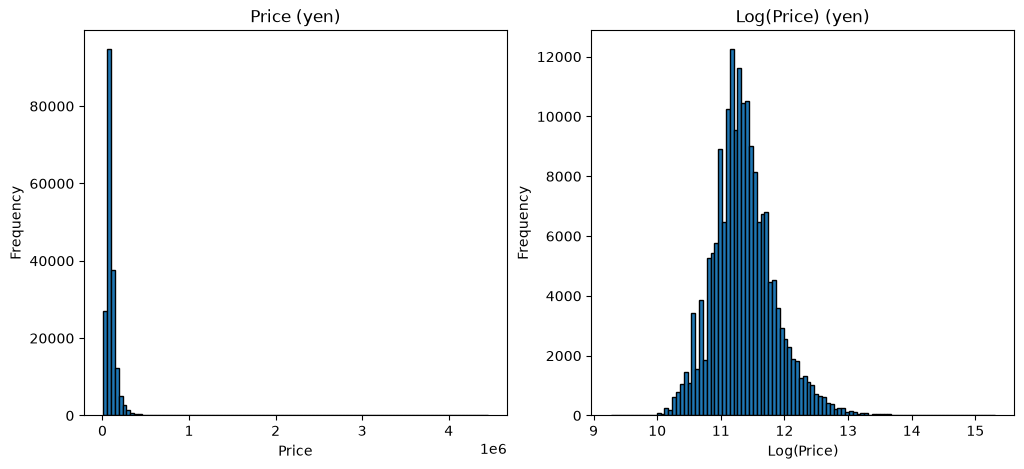

In [6]:
# histogram of price_yen and np.log(price_yen) to see if log transform is needed using matplotlib 
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df["Price_yen"], bins=100, edgecolor='black')
plt.title("Price (yen)")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(np.log(df["Price_yen"]), bins=100, edgecolor='black')
plt.title("Log(Price) (yen)")
plt.xlabel("Log(Price)")
plt.ylabel("Frequency")

plt.show()

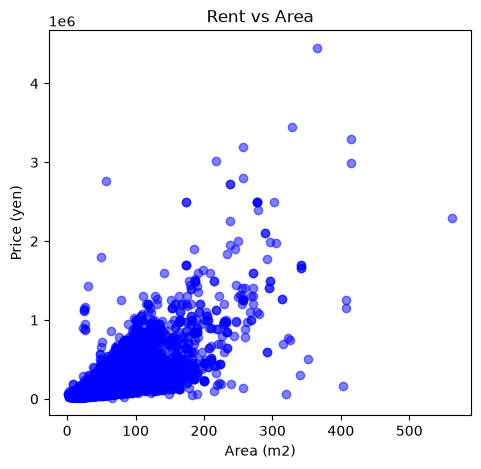

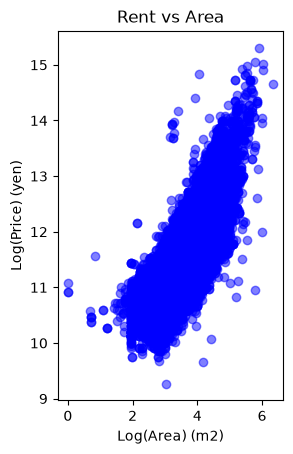

In [7]:
# Rent Vs Area Scatter plot to see if there is a linear relationship between area_m2 and Price_yen, also do log-log comparison, alpha=0.5, color='blue'

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["area_m2"], df["Price_yen"], alpha=0.5, color='blue')
plt.xlabel("Area (m2)")
plt.ylabel("Price (yen)")
plt.title("Rent vs Area")
plt.show()

plt.subplot(1, 2, 2)
plt.scatter(np.log(df["area_m2"]), np.log(df["Price_yen"]), alpha=0.5, color='blue')
plt.xlabel("Log(Area) (m2)")
plt.ylabel("Log(Price) (yen)")  
plt.title("Rent vs Area")
plt.show()




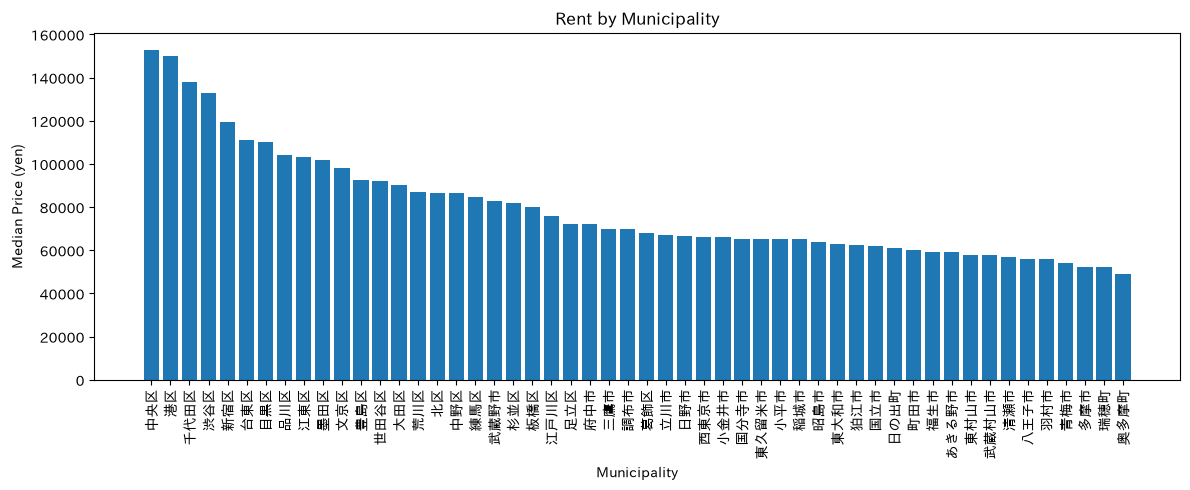

In [8]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # Adds Japanese font support to Matplotlib

median_rent = (
    df.groupby("municipality")["Price_yen"]
      .median()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
plt.bar(median_rent.index, median_rent.values)

plt.xticks(rotation=90)
plt.xlabel("Municipality")
plt.ylabel("Median Price (yen)")
plt.title("Rent by Municipality")
plt.tight_layout()
plt.show()

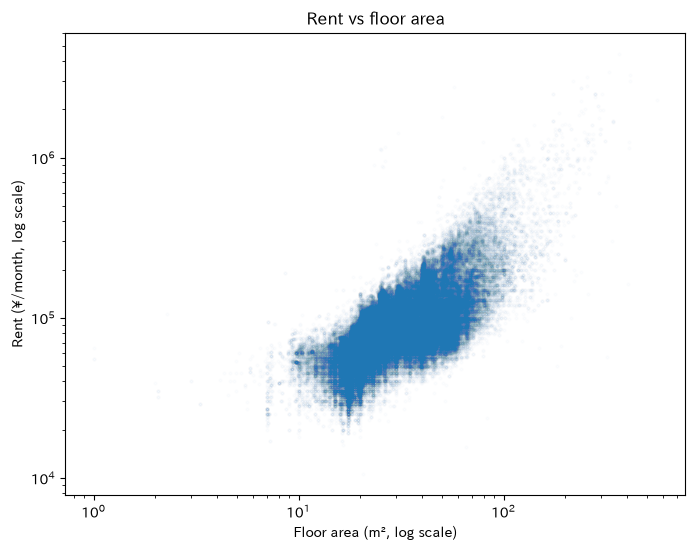

183490 0.6818015365346907


In [9]:
d = df[(df["area_m2"] > 0) & (df["Price_yen"] > 0)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d["area_m2"], d["Price_yen"], s=4, alpha=0.01)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Floor area (m², log scale)")
ax.set_ylabel("Rent (¥/month, log scale)")
ax.set_title("Rent vs floor area")
plt.show()

print(len(d), np.corrcoef(np.log(d["area_m2"]), np.log(d["Price_yen"]))[0, 1])

findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not

                    median      n
walk_min_nearest                 
1.0               100000.0   5907
2.0                95000.0  10475
3.0                92000.0  15077
4.0                92000.0  15498
5.0                87000.0  21892
6.0                88000.0  14833
7.0                83200.0  16335
8.0                80000.0  15233
9.0                85000.0  11777
10.0               76000.0  13258
11.0               78500.0   5452
12.0               72000.0   6975
13.0               72000.0   5771
14.0               72000.0   3717
15.0               69000.0   5098
16.0               69000.0   1859
17.0               70000.0   2430
18.0               69000.0   2306
19.0               69000.0   1216
20.0               68000.0   1869


findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Meiryo' not

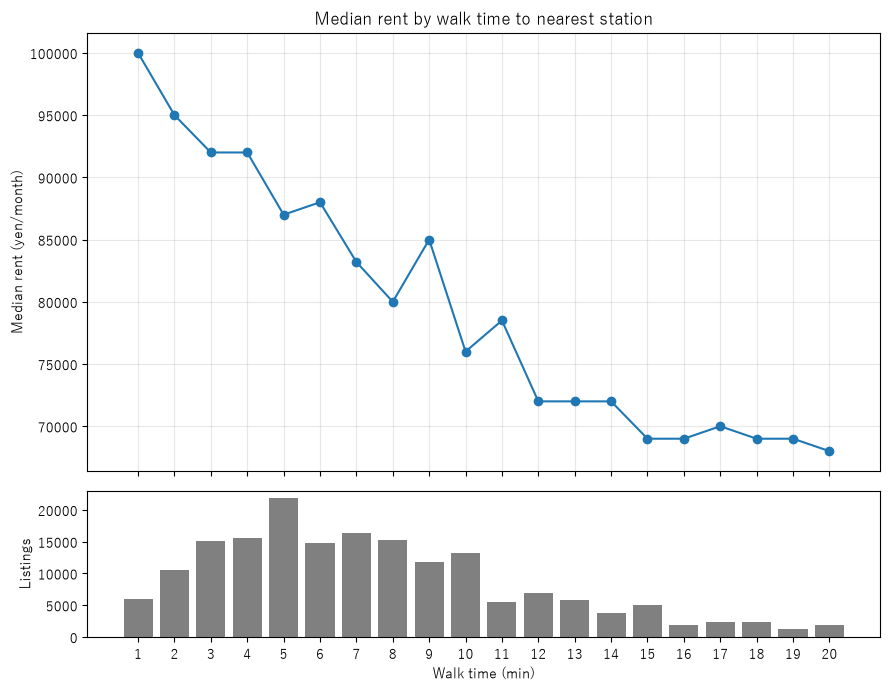

In [12]:


plt.rcParams["font.family"] = ["Yu Gothic", "Meiryo", "MS Gothic", "DejaVu Sans"]  # Windows Japanese fonts

d = df[df["walk_min_nearest"].notna() & (df["walk_min_nearest"] <= 20)]
g = d.groupby("walk_min_nearest")["Price_yen"].agg(median="median", n="size")
print(g)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(g.index, g["median"], marker="o", color="tab:blue")
ax1.set_ylabel("Median rent (yen/month)")
ax1.set_title("Median rent by walk time to nearest station")
ax1.grid(alpha=0.3)

ax2.bar(g.index, g["n"], color="gray")
ax2.set_ylabel("Listings")
ax2.set_xlabel("Walk time (min)")
ax2.set_xticks(range(1, 21))

plt.tight_layout()
plt.savefig("../docs/walk_vs_rent.png", dpi=150)
plt.show()

## My observations
- Highest rent is ofc 1 min to the station with n=5907
- Highest number of cound is at 5 min walking distance about (Around 22k)
- Rent unusually increases from 80k->85k from 8 -> 9 minutes (maybe a cluster of expensive municipality) (less number of n)
- same with 10 min -> 11 min , however the number of buildings are a lot less (13k -> 5k)

             median      n
age_years                 
0          108000.0  29272
1          115000.0   2615
2          105000.0   4979
5           94000.0   3635
10          85000.0   2139
20          82000.0   2476
30          64000.0   5985
40          70000.0   1512
43          70000.0   1037
44          70000.0    894
45          72000.0    722
46          70000.0    750
50          73000.0    685
60          62000.0     61


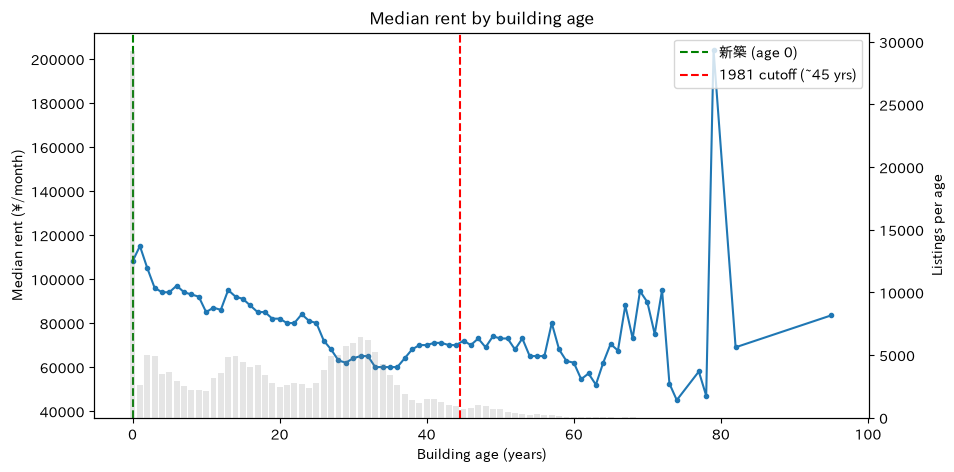

In [11]:
# age_years vs Price_yen 
d = df[df["age_years"].notna() & (df["age_years"] < 99)]   # exclude the 4 capped 築99年以上 rows
g = d.groupby("age_years")["Price_yen"].agg(median="median", n="size")
print(g.loc[[0, 1, 2, 5, 10, 20, 30, 40, 43, 44, 45, 46, 50, 60]].round(0))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(g.index, g["median"], marker="o", markersize=3)
ax1.axvline(0, color="green", linestyle="--", label="新築 (age 0)")
ax1.axvline(44.5, color="red", linestyle="--", label="1981 cutoff (~45 yrs)")
ax1.set_xlabel("Building age (years)")
ax1.set_ylabel("Median rent (¥/month)")
ax1.legend(loc="upper right")

ax2 = ax1.twinx()
ax2.bar(g.index, g["n"], alpha=0.2, color="gray")
ax2.set_ylabel("Listings per age")

ax1.set_title("Median rent by building age")
plt.show()
